# 1. The Lichess puzzle dataset

The Lichess puzzle database is the training data for PuzzleNet and the main puzzle pool of the application.
This notebook describes what the data looks like after cleaning.

**Source:** `data/processed/puzzles_full.parquet`, built by `scripts/build_puzzle_dataset.py` from the
[Lichess puzzle database](https://database.lichess.org/#puzzles). The data is too large for GitHub, so to re-run
this notebook download the CSV into `DataSets/` and run that script first.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pyarrow.compute as pc
import pyarrow.parquet as pq
from nb_utils import ROOT, figures
import pandas as pd
from src.data.puzzle_loader import resolve_primary_category

pd.set_option('display.max_columns', None, 'display.width', 120, 'display.max_colwidth', 45)
path = ROOT / 'data/processed/puzzles_full.parquet'
RAW_PUZZLES = 6_014_381      # rows of the downloaded CSV
parquet = pq.ParquetFile(path)
table = parquet.read(columns=['Rating', 'RatingDeviation', 'Popularity', 'NbPlays', 'Themes'])
print(f'after cleaning: {table.num_rows:,} puzzles')
print(f'removed by cleaning: {RAW_PUZZLES - table.num_rows:,} ({(RAW_PUZZLES - table.num_rows) / RAW_PUZZLES:.1%})')

after cleaning: 5,877,641 puzzles
removed by cleaning: 136,740 (2.3%)


## The first rows

In [2]:
columns = ['PuzzleId', 'FEN', 'Moves', 'Rating', 'RatingDeviation', 'Popularity', 'NbPlays', 'Themes']
next(parquet.iter_batches(batch_size=5, columns=columns)).to_pandas()

,PuzzleId,FEN,Moves,Rating,RatingDeviation,Popularity,NbPlays,Themes
0,00008,r6k/pp2r2p/4Rp1Q/3p4/8/1N1P2R1/PqP2bPP/7K...,f2g3 e6e7 b2b1 b3c1 b1c1 h6c1,1862,76,95,9697,crushing hangingPiece long middlegame
1,0000D,5rk1/1p3ppp/pq3b2/8/8/1P1Q1N2/P4PPP/3R2K1...,d3d6 f8d8 d6d8 f6d8,1579,73,96,36672,advantage endgame short
2,0008Q,8/4R3/1p2P3/p4r2/P6p/1P3Pk1/4K3/8 w - - 1 64,e7f7 f5e5 e2f1 e5e6,1385,80,92,765,advantage endgame rookEndgame short
3,0009B,r2qr1k1/b1p2ppp/pp4n1/P1P1p3/4P1n1/B2P2Pb...,b6c5 e2g4 h3g4 d1g4,1084,74,88,606,advantage middlegame short
4,000Pw,6k1/5p1p/4p3/4q3/3nN3/2Q3P1/PP3P1P/6K1 w ...,e4d2 d4e2 g1f1 e2c3,1550,75,92,626,crushing endgame fork short


## Numeric columns

In [3]:
numeric = table.select(['Rating', 'RatingDeviation', 'Popularity', 'NbPlays']).to_pandas()
numeric.describe(percentiles=[.05, .5, .95]).round(1)

,Rating,RatingDeviation,Popularity,NbPlays
count,5877641.0,5877641.0,5877641.0,5877641.0
mean,1475.5,84.0,87.0,1737.2
std,550.3,12.4,12.5,4623.5
min,399.0,45.0,0.0,6.0
5%,650.0,75.0,63.0,33.0
50%,1425.0,79.0,90.0,393.0
95%,2443.0,110.0,100.0,8442.0
max,3327.0,150.0,100.0,312644.0


## Rating and category

The primary category of each puzzle is resolved from its themes by `resolve_primary_category`, the same rule the rest of the system uses.

In [4]:
counts = pc.value_counts(table['Themes'].combine_chunks())
categories = {}
for entry in counts.to_pylist():
    category = resolve_primary_category(entry['values'] or '')
    categories[category] = categories.get(category, 0) + entry['counts']
categories = pd.Series(categories).sort_values(ascending=False)
share = (categories / categories.sum()).round(4)
pd.DataFrame({'puzzles': categories, 'share': share})

,puzzles,share
Mating Pattern,1849331,0.3146
General,749663,0.1275
Fork,708178,0.1205
Endgame,534884,0.0910
Pin,279010,0.0475
Discovered Attack,242712,0.0413
Hanging Piece,184858,0.0315
Deflection,180863,0.0308
Quiet Move,161114,0.0274
King Safety,136506,0.0232


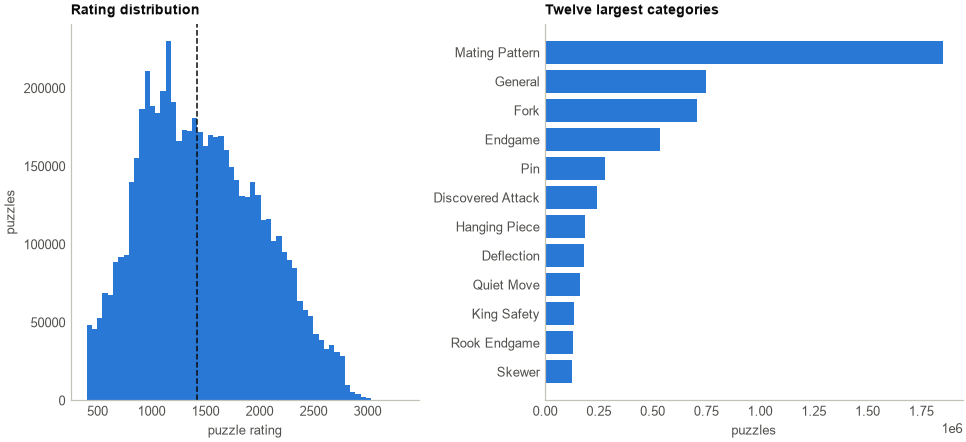

In [5]:
fig, (a, b) = plt.subplots(1, 2, figsize=(9, 4.2), gridspec_kw={'width_ratios': [1, 1.2]})
a.hist(numeric['Rating'], bins=60, color=figures.BLUE)
a.axvline(numeric['Rating'].median(), color=figures.INK, lw=1, ls='--')
a.set_xlabel('puzzle rating')
a.set_ylabel('puzzles')
a.set_title('Rating distribution')
top = categories.head(12)[::-1]
b.barh(top.index, top.values, color=figures.BLUE)
b.set_xlabel('puzzles')
b.set_title('Twelve largest categories')
fig.tight_layout()
figures.save(fig, 'dataset_overview')

## Observations

- Cleaning removed only 2.3% of the puzzles, so the training data keeps almost the whole database.
- Ratings run from 399 to 3327 with a median of 1425, so the network sees examples for beginners and experts alike.
- The categories are very unbalanced: Mating Pattern holds 31% of puzzles, while En Passant holds 0.1%. This is why
  macro recall is reported alongside agreement in notebook 4, because agreement alone favours the large categories.